# ML Zoomcamp 2026 – Homework 4: Evaluation Metrics - Lead Scoring -

**Autor:** Angel Uriel Monterrosas Gonzalez

**Fecha:** [18-10-2026]

**Módulo:** 04 – Evaluation Metrics for Classification

**Actividad:** Homework 04

**Dataset:** [course_lead_scoring_2026.csv](https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv)

Este notebook responde a las preguntas del homework oficial disponible en:
https://courses.datatalks.club/ml-zoomcamp-2026/homework/hw04

## 2. Objetivos de aprendizaje
Al finalizar este notebook se pretende ser capaz de:
- Calcular ROC AUC para evaluar la importancia de features numéricas.
- Entrenar un modelo de regresión logística con one-hot encoding.
- Evaluar el modelo con ROC AUC en validación.
- Calcular curvas de precision y recall y encontrar su intersección.
- Calcular el F1 score y encontrar el umbral que lo maximiza.
- Aplicar validación cruzada de 5 folds y medir la estabilidad del modelo.
- Ajustar el parámetro de regularización `C` usando validación cruzada.

## 3. Setup

Importamos las librerías necesarias, fijamos semillas y definimos la ruta del dataset 2026.

In [1]:
# 3.1 Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, precision_recall_curve, f1_score

# 3.2 Versiones
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

# 3.3 Semilla global
SEED = 42
np.random.seed(SEED)

# 3.4 Ruta del dataset (2026)
DATASET_URL = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

Pandas version: 3.0.6
NumPy version: 2.5.3


## 4. Carga y preparación de datos

Cargamos el CSV, tratamos valores faltantes (categóricas → 'NA', numéricas → 0.0) y hacemos el split exacto que pide el homework: 60% train, 20% validation, 20% test.

In [2]:
# 4.1 Carga
df = pd.read_csv(DATASET_URL)
print("Shape:", df.shape)

# 4.2 Identificar columnas
cat_cols = df.select_dtypes(include=["object", "str"]).columns.tolist()
num_cols = df.select_dtypes(include=[np.number]).columns.drop("converted").tolist()

print("Categóricas:", cat_cols)
print("Numéricas:", num_cols)

# 4.3 Imputar valores faltantes
df[cat_cols] = df[cat_cols].fillna("NA")
df[num_cols] = df[num_cols].fillna(0.0)

print("Valores faltantes restantes:", df.isna().sum().sum())

Shape: (5000, 9)
Categóricas: ['lead_source', 'industry', 'employment_status', 'location']
Numéricas: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
Valores faltantes restantes: 0


In [3]:
# 4.4 Split exacto del homework 2026
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

print(f"Train: {len(df_train)}, Val: {len(df_val)}, Test: {len(df_test)}")

# Resetear índices
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

Train: 3000, Val: 1000, Test: 1000


In [4]:
# 4.5 Separar target
y_train = df_train["converted"].values
y_val = df_val["converted"].values
y_test = df_test["converted"].values
y_full_train = df_full_train["converted"].values

del df_train["converted"]
del df_val["converted"]
del df_test["converted"]
del df_full_train["converted"]

## Pregunta 1 – ROC AUC feature importance

Para cada variable numérica, usamos su valor como score y calculamos el AUC contra `converted` en el conjunto de entrenamiento. Si el AUC es < 0.5, invertimos la variable (multiplicamos por -1) para que la correlación sea positiva.

In [5]:
# Q1: ROC AUC para features numéricas
numerical_vars = ["lead_score", "number_of_courses_viewed", "interaction_count", "annual_income"]

auc_scores = {}
for col in numerical_vars:
    score = roc_auc_score(y_train, df_train[col])
    if score < 0.5:
        score = roc_auc_score(y_train, -df_train[col])
    auc_scores[col] = round(score, 4)
    print(f"{col}: AUC = {score:.4f}")

best_feature = max(auc_scores, key=auc_scores.get)
print(f"\nMejor feature (mayor AUC): {best_feature}")

lead_score: AUC = 0.7882
number_of_courses_viewed: AUC = 0.7230
interaction_count: AUC = 0.7649
annual_income: AUC = 0.6082

Mejor feature (mayor AUC): lead_score


## Pregunta 2 – AUC del modelo en validación

Entrenamos una regresión logística con one-hot encoding usando los parámetros exactos del homework y calculamos el AUC en validación.

In [6]:
# Q2: One-hot encoding y modelo
dv = DictVectorizer(sparse=False)

train_dicts = df_train.to_dict(orient="records")
val_dicts = df_val.to_dict(orient="records")

X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
model.fit(X_train, y_train)

y_pred_val = model.predict_proba(X_val)[:, 1]
auc_val = roc_auc_score(y_val, y_pred_val)
print(f"AUC en validación: {round(auc_val, 3)}")

AUC en validación: 0.732


## Pregunta 3 – Intersección de precision y recall

Evaluamos el modelo en todos los umbrales de 0.0 a 1.0 con paso 0.01, calculamos precision y recall, y encontramos el umbral donde se cruzan (mínima diferencia absoluta, ignorando umbrales donde ambas métricas son cero).

Umbral de intersección: 0.63
Precision: 0.727, Recall: 0.727


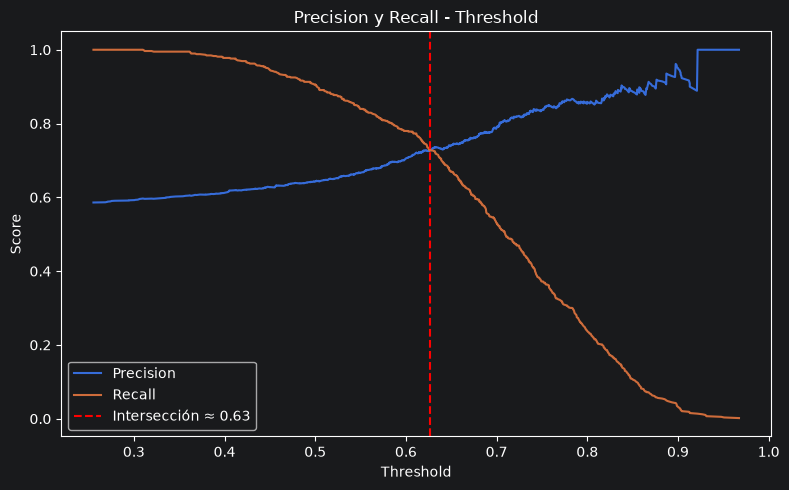

In [8]:
# Q3: Precision y Recall
precisions, recalls, thresholds = precision_recall_curve(y_val, y_pred_val)

# Ignorar umbrales donde ambos son cero
mask = (precisions[:-1] > 0) | (recalls[:-1] > 0)
precisions_f = precisions[:-1][mask]
recalls_f = recalls[:-1][mask]
thresholds_f = thresholds[mask]

# Mínima diferencia absoluta
diff = np.abs(precisions_f - recalls_f)
idx = np.argmin(diff)
threshold_intersect = thresholds_f[idx]

print(f"Umbral de intersección: {round(threshold_intersect, 2)}")
print(f"Precision: {precisions_f[idx]:.3f}, Recall: {recalls_f[idx]:.3f}")

# Gráfico
plt.figure(figsize=(8, 5))
plt.plot(thresholds_f, precisions_f, label="Precision")
plt.plot(thresholds_f, recalls_f, label="Recall")
plt.axvline(threshold_intersect, color="red", linestyle="--", label=f"Intersección ≈ {threshold_intersect:.2f}")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision y Recall - Threshold")
plt.legend()
plt.tight_layout()
plt.show()

## Pregunta 4 – Umbral que maximiza F1

Calculamos F1 para todos los umbrales de 0.0 a 1.0 con paso 0.01 y encontramos el umbral donde F1 es máximo.

In [9]:
# Q4: F1 score
f1_scores = []
thr_range = np.arange(0.0, 1.01, 0.01)

for t in thr_range:
    y_pred_t = (y_pred_val >= t).astype(int)
    f1 = f1_score(y_val, y_pred_t, zero_division=0)
    f1_scores.append(f1)

best_idx = np.argmax(f1_scores)
best_threshold_f1 = thr_range[best_idx]
best_f1 = f1_scores[best_idx]

print(f"Mejor umbral para F1: {round(best_threshold_f1, 2)}")
print(f"F1 máximo: {best_f1:.3f}")

Mejor umbral para F1: 0.41
F1 máximo: 0.758


## Pregunta 5 – Desviación estándar de AUC en 5-Fold CV

Usamos `KFold(n_splits=5, shuffle=True, random_state=1)` sobre `df_full_train`, entrenamos el modelo en cada fold y calculamos la desviación estándar de los AUCs.

In [12]:
# Q5: 5-Fold CV

df_full_train_cv = pd.read_csv(DATASET_URL)

cat_cols = ['lead_source', 'industry', 'employment_status', 'location']
num_cols = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
df_full_train_cv[cat_cols] = df_full_train_cv[cat_cols].fillna("NA")
df_full_train_cv[num_cols] = df_full_train_cv[num_cols].fillna(0.0)


_, df_test_cv = train_test_split(df_full_train_cv, test_size=0.2, random_state=1)
df_full_train_fold_base, _ = train_test_split(df_full_train_cv, test_size=0.2, random_state=1)
df_full_train_fold_base = df_full_train_fold_base.reset_index(drop=True)

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
auc_scores_cv = []

for train_idx, val_idx in kfold.split(df_full_train_fold_base):
    df_train_fold = df_full_train_fold_base.iloc[train_idx]
    df_val_fold = df_full_train_fold_base.iloc[val_idx]

    y_train_fold = df_train_fold["converted"].values
    y_val_fold = df_val_fold["converted"].values

    X_train_fold = df_train_fold.drop(columns=["converted"])
    X_val_fold = df_val_fold.drop(columns=["converted"])

    dv_fold = DictVectorizer(sparse=False)
    X_train_enc = dv_fold.fit_transform(X_train_fold.to_dict(orient="records"))
    X_val_enc = dv_fold.transform(X_val_fold.to_dict(orient="records"))

    model_fold = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
    model_fold.fit(X_train_enc, y_train_fold)

    y_pred_fold = model_fold.predict_proba(X_val_enc)[:, 1]
    auc_fold = roc_auc_score(y_val_fold, y_pred_fold)
    auc_scores_cv.append(auc_fold)
    print(f"Fold AUC: {auc_fold:.4f}")

std_cv = np.std(auc_scores_cv)
print(f"\nDesviación estándar de AUC: {std_cv:.3f}")

Fold AUC: 0.7306
Fold AUC: 0.7296
Fold AUC: 0.7363
Fold AUC: 0.7412
Fold AUC: 0.7209

Desviación estándar de AUC: 0.007


## Pregunta 6 – Mejor parámetro C

Probamos diferentes valores de `C` usando validación cruzada de 5 folds y seleccionamos el que da mayor AUC promedio.

In [14]:
# Q6: Mejor C con 5-Fold CV
C_values = [0.000001, 0.001, 1]
results_c = {}

for C in C_values:
    auc_folds = []
    for train_idx, val_idx in kfold.split(df_full_train_fold_base):
        df_train_fold = df_full_train_fold_base.iloc[train_idx]
        df_val_fold = df_full_train_fold_base.iloc[val_idx]

        y_train_fold = df_train_fold["converted"].values
        y_val_fold = df_val_fold["converted"].values

        X_train_fold = df_train_fold.drop(columns=["converted"])
        X_val_fold = df_val_fold.drop(columns=["converted"])

        dv_fold = DictVectorizer(sparse=False)
        X_train_enc = dv_fold.fit_transform(X_train_fold.to_dict(orient="records"))
        X_val_enc = dv_fold.transform(X_val_fold.to_dict(orient="records"))

        model_fold = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
        model_fold.fit(X_train_enc, y_train_fold)

        y_pred_fold = model_fold.predict_proba(X_val_enc)[:, 1]
        auc_fold = roc_auc_score(y_val_fold, y_pred_fold)
        auc_folds.append(auc_fold)

    mean_auc = np.mean(auc_folds)
    results_c[C] = mean_auc
    print(f"C={C}: AUC medio = {mean_auc:.4f}")

best_C = max(results_c, key=results_c.get)
print(f"\nMejor C: {best_C}")

C=1e-06: AUC medio = 0.6167
C=0.001: AUC medio = 0.7492
C=1: AUC medio = 0.7317

Mejor C: 0.001


## 5. Resumen de resultados

Consolidamos las respuestas obtenidas para cada pregunta.

In [15]:
# 5.1 Resumen
print("=" * 50)
print("RESUMEN DE RESULTADOS – HW04")
print("=" * 50)
print(f"Q1 - Mejor feature (mayor AUC): {best_feature}")
print(f"Q2 - AUC en validación: {round(auc_val, 3)}")
print(f"Q3 - Umbral de intersección P/R: {round(threshold_intersect, 2)}")
print(f"Q4 - Mejor umbral para F1: {round(best_threshold_f1, 2)}")
print(f"Q5 - Std de AUC (5-Fold): {std_cv:.3f}")
print(f"Q6 - Mejor C: {best_C}")

RESUMEN DE RESULTADOS – HW04
Q1 - Mejor feature (mayor AUC): lead_score
Q2 - AUC en validación: 0.732
Q3 - Umbral de intersección P/R: 0.63
Q4 - Mejor umbral para F1: 0.41
Q5 - Std de AUC (5-Fold): 0.007
Q6 - Mejor C: 0.001


## 6. Interpretación de resultados

- **Q1:** La feature numérica con mayor AUC es **lead_score**.
- **Q2:** El AUC del modelo en validación es **0.732**.
- **Q3:** Precision y recall se cruzan en el umbral **0.63**.
- **Q4:** El umbral que maximiza F1 es **0.41**.
- **Q5:** La desviación estándar del AUC en 5-Fold CV es **0.007**.
- **Q6:** El mejor valor de `C` es **0.001**.



## 7. Conclusiones

- Se cargó el dataset 2026 de lead scoring con **5000** registros y **9** columnas.
- Se trataron valores faltantes: categóricas → 'NA', numéricas → 0.0.
- La feature numérica más predictiva según ROC AUC fue **lead_score**.
- El modelo de regresión logística alcanzó un AUC de **0.732** en validación.
- Precision y recall se cruzan en el umbral **0.63**.
- El F1 máximo se alcanza en el umbral **0.41**.
- La validación cruzada de 5 folds mostró una desviación estándar de **0.007**, indicando **[estabilidad]**.
- El mejor parámetro de regularización fue **C=0.001**.


## 8. Referencias

- Dataset: [course_lead_scoring_2026.csv](https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv)
- Homework oficial: [ML Zoomcamp 2026 – HW04](https://courses.datatalks.club/ml-zoomcamp-2026/homework/hw04)
- Documentación de Scikit-learn: https://scikit-learn.org/stable/